In [2]:
from sklearn.tree import DecisionTreeClassifier as DT
from sklearn.ensemble import RandomForestClassifier as skrf
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score
from sklearn.metrics import classification_report, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import pandas as pd
from osgeo import gdal
from pathlib import Path
import os
from sklearn import tree
from matplotlib import pyplot as plt

In [48]:
os. chdir(r'E:\CTECH\GEOINT\project')
file_name= 'SentinelTinkitamAPR2021.tif'
ds= gdal.Open(file_name)

[[0.66162767 0.63921737 0.61530196 ... 0.55152672 0.6268101  0.61251086]
 [0.64156298 0.61604998 0.59636731 ... 0.55151515 0.60685225 0.59662447]
 [0.60619367 0.58283172 0.60761502 ... 0.60068847 0.61004184 0.60770578]
 ...
 [0.57792208 0.57086441 0.55794916 ... 0.55981357 0.4256662  0.46503244]
 [0.56398941 0.52698552 0.52119701 ... 0.5310702  0.44375683 0.57470903]
 [0.54692557 0.53046304 0.55172414 ... 0.52927991 0.50978565 0.64808917]]


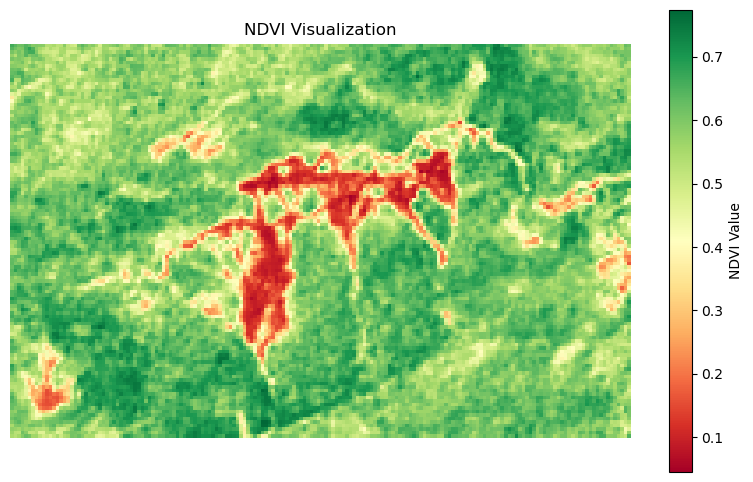

Text(0.5, 1.0, 'NDVI Zone')

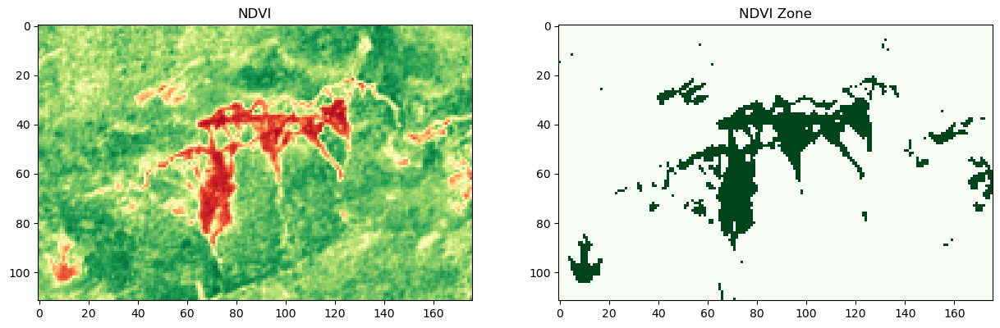

In [49]:
from osgeo import gdal
import numpy as np
import matplotlib.pyplot as plt

# Define file paths

image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Near-Infrared band (Band 8 for Sentinel-2)

# Open the NIR and Red bands
image_dataset = gdal.Open(image_path)

# Read data as arrays
nir_band = image_dataset.GetRasterBand(7).ReadAsArray().astype('float')
red_band = image_dataset.GetRasterBand(3).ReadAsArray().astype('float')

# Compute NDVI
ndvi = (nir_band - red_band) / (nir_band + red_band )  # Adding a small value to avoid division by zero

print(ndvi)

def classify_ndvi(ndvi_array):
    """
    Classifies NDVI values into categories.
    """
    ndvi_class = np.zeros_like(ndvi_array, dtype=np.uint8)

    # Define NDVI classes
    ndvi_class[(ndvi_array <= -1.0)] = 1   # No data
    ndvi_class[(ndvi_array > -1.0) & (ndvi_array < 0.0)] = 1  # Water
    ndvi_class[(ndvi_array >= 0.0) & (ndvi_array < 0.2)] = 1  # Barren land (rock, sand, snow)
    ndvi_class[(ndvi_array >= 0.2) & (ndvi_array < 0.4)] = 1  # Sparse vegetation
    ndvi_class[(ndvi_array >= 0.4) & (ndvi_array < 0.6)] = 0  # Moderate vegetation
    ndvi_class[(ndvi_array >= 0.6) & (ndvi_array <= 1.0)] = 0  # Dense vegetation

    return ndvi_class

# Apply classification
ndvi_classes = classify_ndvi(ndvi)

plt.figure(figsize=(10, 6))
plt.imshow(ndvi, cmap='RdYlGn')  # Red-Yellow-Green colormap
plt.colorbar(label="NDVI Value")
plt.title("NDVI Visualization")
plt.axis("off")  # Hide axis
plt.show()

fig, ax = plt.subplots(1,2,figsize=(15, 10))

ax[0].imshow(ndvi, cmap='RdYlGn')
ax[0].set_title('NDVI')

ax[1].imshow(ndvi_classes, cmap='Greens')
ax[1].set_title('NDVI Zone')


       X    Y     NDVI_Class
0     10   10  Non-Landslide
1     15   10  Non-Landslide
2     20   10  Non-Landslide
3     25   10  Non-Landslide
4     30   10  Non-Landslide
..   ...  ...            ...
584  140  100  Non-Landslide
585  145  100  Non-Landslide
586  150  100  Non-Landslide
587  155  100  Non-Landslide
588  160  100  Non-Landslide

[589 rows x 3 columns]


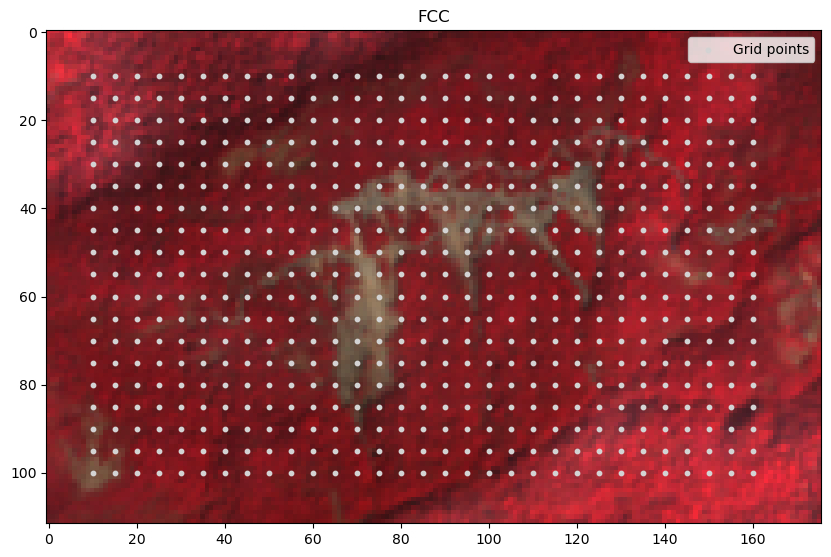

In [50]:
multidata = ds.ReadAsArray(band_list=[7,3,2])
multidata = multidata.astype('float')
multidata/=np.max(multidata)

multidata = np.transpose(multidata, axes=(1,2,0))

plt.figure(figsize=(10,10))
plt.title('FCC')
plt.imshow(multidata)

# Create grid points at intervals of 5
x_vals = np.arange(10, 161, 5)
y_vals = np.arange(10, 101, 5)
xx, yy = np.meshgrid(x_vals, y_vals)

# Plot the grid points
plt.scatter(xx, yy, c='lightgray', s=10, label='Grid points')

# Plot the given vegetation points

plt.legend()

import pandas as pd

# Assume spatial coordinates correspond directly to array indices
# Adjust this part if geotransform is needed
grid_points = []

for x, y in zip(xx.flatten(), yy.flatten()):
    col = int(x)
    row = int(y)
    if 0 <= row < ndvi_classes.shape[0] and 0 <= col < ndvi_classes.shape[1]:
        ndvi_zone = ndvi_classes[row, col]
        grid_points.append({'X': x, 'Y': y, 'NDVI_Class': 'Non-Landslide' if ndvi_zone == 0 else 'Landslide'})

# Create a DataFrame
ndvi_table = pd.DataFrame(grid_points)

# Display the table
print(ndvi_table)

# Optional: save to CSV
ndvi_table.to_csv('ndvi_classification_grid.csv', index=False)


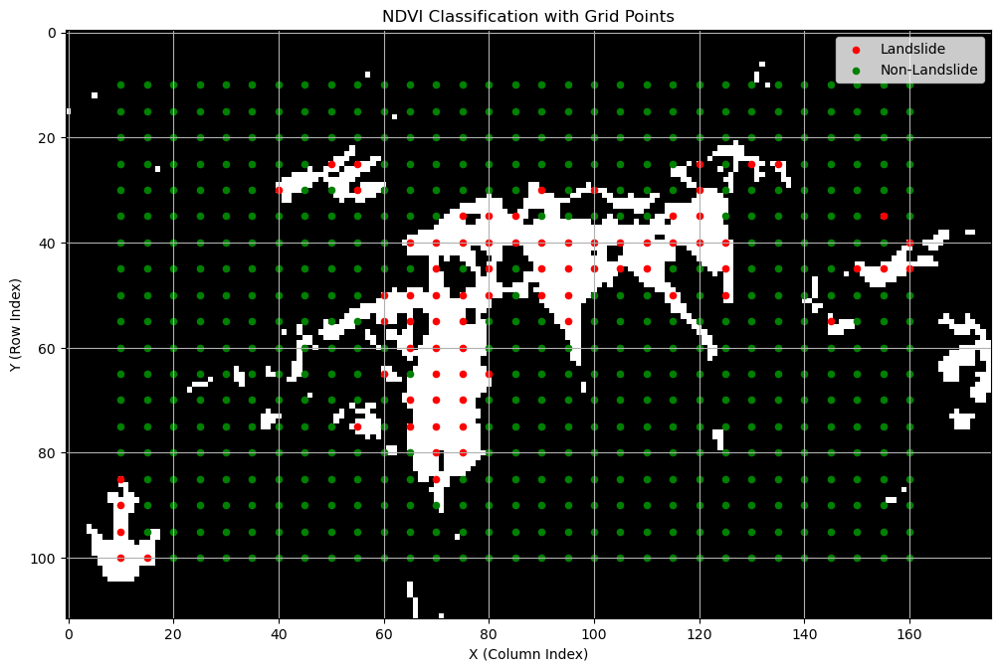

In [51]:
landslide_pts = ndvi_table[ndvi_table['NDVI_Class'] == 'Landslide']
non_landslide_pts = ndvi_table[ndvi_table['NDVI_Class'] == 'Non-Landslide']

plt.figure(figsize=(12, 12))
plt.title('NDVI Classification with Grid Points')

# Show NDVI class image in background
plt.imshow(ndvi_classes==1, cmap='gray')

# Plot Landslide points (NDVI_Class = 1)
plt.scatter(landslide_pts['X'], landslide_pts['Y'], c='red', s=20, label='Landslide')

# Plot Non-Landslide points (NDVI_Class = 0)
plt.scatter(non_landslide_pts['X'], non_landslide_pts['Y'], c='green', s=20, label='Non-Landslide')

plt.legend()
plt.xlabel('X (Column Index)')
plt.ylabel('Y (Row Index)')
plt.grid(True)
plt.show()

In [52]:
dataset = [7, 4, 3, 2]  # Adjust as per your dataset (7=NIR, 4=Red, 3=Green)

# Read bands into arrays
fcc_bands = [ds.GetRasterBand(band).ReadAsArray().astype('float') for band in dataset]

# Names for the bands
band_names = ['NIR', 'Red', 'Green', 'Blue']

# Loop through the grid points and extract pixel values from each band
fcc_values = []

for idx, row in ndvi_table.iterrows():
    y = int(row['Y'])  # Row index
    x = int(row['X'])  # Column index
    if 0 <= y < fcc_bands[0].shape[0] and 0 <= x < fcc_bands[0].shape[1]:
        pixel_vals = {
            'X': x,
            'Y': y,
            'NDVI_Class': row['NDVI_Class'],
        }
        for i, band in enumerate(fcc_bands):
            pixel_vals[band_names[i]] = band[y, x]
        fcc_values.append(pixel_vals)

# Create DataFrame
fcc_df = pd.DataFrame(fcc_values)

# Show the table
print(fcc_df.head())

# Optional: Save to CSV
fcc_df.to_csv('fcc_pixel_values.csv', index=False)

    X   Y     NDVI_Class     NIR     Red  Green    Blue
0  10  10  Non-Landslide  2272.0  1447.0  821.0  1010.0
1  15  10  Non-Landslide  2508.0  1170.0  790.0   993.0
2  20  10  Non-Landslide  2742.0  1153.0  744.0   938.0
3  25  10  Non-Landslide  2184.0   997.0  591.0   735.0
4  30  10  Non-Landslide  1701.0   880.0  508.0   575.0


In [53]:
# Drop X and Y columns
fcc_df = fcc_df.drop(columns=['X', 'Y'])
fcc_df['ndvi'] = fcc_df['NDVI_Class'].apply(lambda x: 1 if x == 'Landslide' else 0)
fcc_df = fcc_df.drop(columns=['NDVI_Class'])

# Show the updated table
print(fcc_df.head())

# Optional: Save to CSV without X and Y
fcc_df.to_csv('fcc_pixel_values5.csv', index=True)


      NIR     Red  Green    Blue  ndvi
0  2272.0  1447.0  821.0  1010.0     0
1  2508.0  1170.0  790.0   993.0     0
2  2742.0  1153.0  744.0   938.0     0
3  2184.0   997.0  591.0   735.0     0
4  1701.0   880.0  508.0   575.0     0


In [54]:
df=pd.read_csv(r'fcc_pixel_values5.csv', index_col=0)
df.head()

,NIR,Red,Green,Blue,ndvi
0,2272.0,1447.0,821.0,1010.0,0
1,2508.0,1170.0,790.0,993.0,0
2,2742.0,1153.0,744.0,938.0,0
3,2184.0,997.0,591.0,735.0,0
4,1701.0,880.0,508.0,575.0,0


In [55]:
y = df.pop('ndvi')
x = df

In [56]:
print(x)

        NIR     Red  Green    Blue
0    2272.0  1447.0  821.0  1010.0
1    2508.0  1170.0  790.0   993.0
2    2742.0  1153.0  744.0   938.0
3    2184.0   997.0  591.0   735.0
4    1701.0   880.0  508.0   575.0
..      ...     ...    ...     ...
584  4109.0  1422.0  787.0  1060.0
585  3044.0  1301.0  731.0   973.0
586  4352.0  1572.0  850.0  1120.0
587  3178.0  1460.0  895.0  1060.0
588  3749.0  1352.0  781.0  1020.0

[589 rows x 4 columns]


In [57]:
print(y)


0      0
1      0
2      0
3      0
4      0
      ..
584    0
585    0
586    0
587    0
588    0
Name: ndvi, Length: 589, dtype: int64


In [58]:
RANDOM_STATE = 42

# Assuming X and y are already defined (features and labels)
X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    random_state=RANDOM_STATE,
    train_size=0.8  # or whatever split ratio you'd like
)

In [59]:
y_train.value_counts(), y_test.value_counts()

(ndvi
 0    409
 1     62
 Name: count, dtype: int64,
 ndvi
 0    102
 1     16
 Name: count, dtype: int64)

In [60]:
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
NIR,471.0,2239.740977,442.924191,1405.0,1955.5,2161.0,2436.0,4352.0
Red,471.0,1040.789809,273.348488,586.0,854.0,971.0,1153.5,2289.0
Green,471.0,654.318471,308.969186,326.0,468.0,549.0,690.0,2140.0
Blue,471.0,712.089172,224.543055,389.0,564.0,635.0,787.5,1710.0


In [61]:
y_train.describe().T

count    471.000000
mean       0.131635
std        0.338453
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000
Name: ndvi, dtype: float64

In [62]:
hyperparameters = {
    'criterion': 'gini',
    'max_depth': None,
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'min_weight_fraction_leaf': 0.0,
    'max_features': 'sqrt',
    'max_leaf_nodes': None,
    'min_impurity_decrease': 0.0,
    'random_state': 42,
    'class_weight': None,
    'ccp_alpha': 0.0,
}


built decision tree

In [17]:
classifier = DT(**hyperparameters)
classifier.fit(X_train, y_train)

DecisionTreeClassifier(max_features='sqrt', random_state=42)

In [18]:
score = classifier.score(X_test,y_test)
print('avg. accuracy:{}'.format(score))

avg. accuracy:0.9830508474576272


In [19]:
test_prediction=classifier.predict(X_test)
print('test performance')
print('----------------------------')
print(classification_report(y_test,test_prediction))

test performance
----------------------------
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       102
           1       0.94      0.94      0.94        16

    accuracy                           0.98       118
   macro avg       0.96      0.96      0.96       118
weighted avg       0.98      0.98      0.98       118



In [20]:
print("Unique types in y_test:", set(type(i) for i in y_test))
print("Unique types in test_predictions:", set(type(i) for i in test_prediction))
print("classifier.classes_:", classifier.classes_)


Unique types in y_test: {<class 'int'>}
Unique types in test_predictions: {<class 'numpy.int64'>}
classifier.classes_: [0 1]


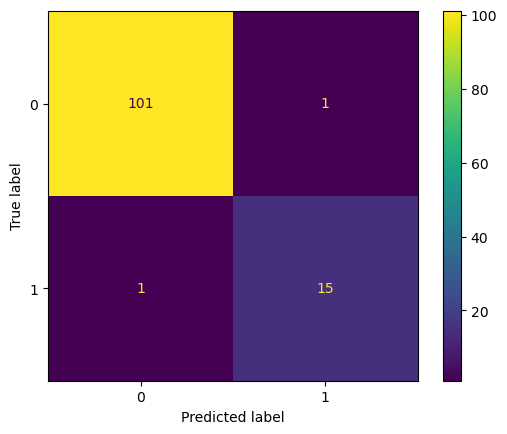

In [21]:
# Convert all to strings
y_test = [str(i) for i in y_test]
test_predictions = [str(i) for i in test_prediction]
labels = list(classifier.classes_.astype(str))

# Confusion matrix
cm = confusion_matrix(y_test, test_predictions, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot()


In [22]:
print("Classes in classifier:", classifier.classes_)
print("Number of classes:", len(classifier.classes_))

Classes in classifier: [0 1]
Number of classes: 2


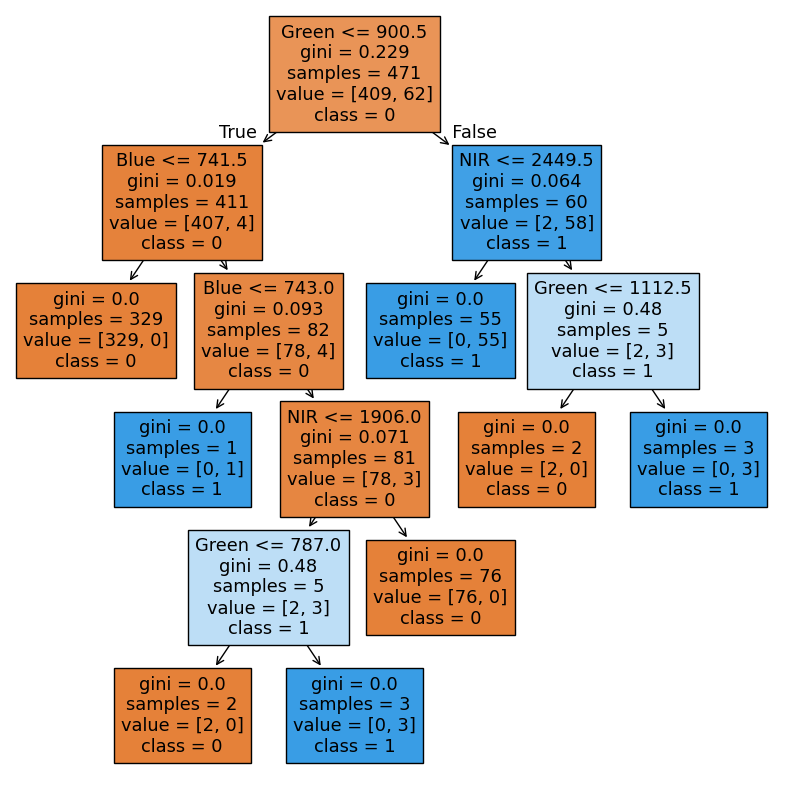

In [23]:
fig, ax = plt.subplots(figsize=(10, 10))
tree.plot_tree(
    classifier,
    feature_names=['NIR', 'Red', 'Green', 'Blue'],
    class_names=classifier.classes_.astype(str),  # Auto-use correct labels
    ax=ax,
    filled=True
)
plt.show()

In [24]:
file_name = ['SentinelTinkitamDEC2020.tif']
data = []

for file in file_name:
    ds = gdal.Open(file)
    bands_array = ds.ReadAsArray(band_list=[7, 4, 3, 2])  # NIR, Red, Green, Blue
    for band in bands_array:
        data.append(band)

# Assign meaningful column names
df = pd.DataFrame({
    'NIR': data[0].ravel(),
    'Red': data[1].ravel(),
    'Green': data[2].ravel(),
    'Blue': data[3].ravel()
})

print(df.head())

    NIR   Red  Green  Blue
0  2743  1235    509   740
1  2975  1322    788   874
2  4159  1322    762   952
3  5272  1520    959  1228
4  4632  1520   1010  1052


In [25]:
fcc_bands[0].shape

(112, 176)

In [26]:
len(df)

19712

In [27]:
data[0].shape

(112, 176)

In [28]:
ndvi_map =classifier.predict(df)
ndvi_map

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

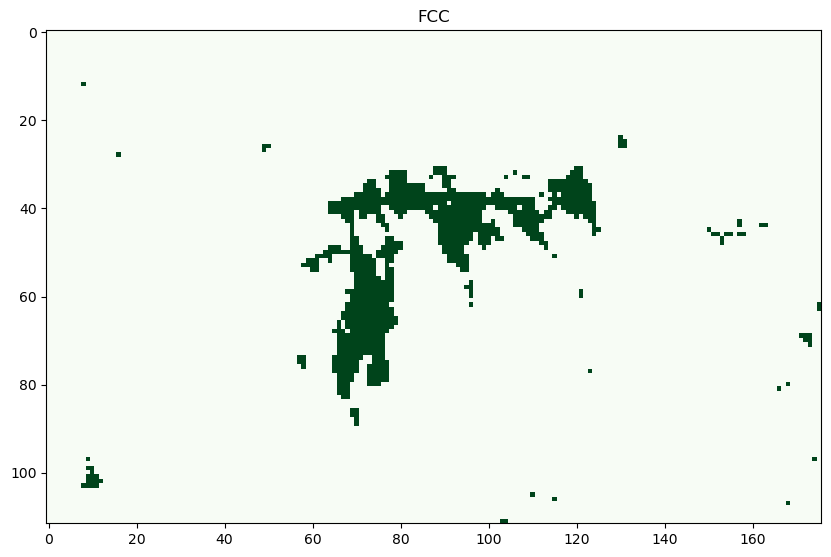

In [30]:
ndvi_map= ndvi_map.reshape(112,176)

map = ndvi_map.astype('float')

plt.figure(figsize=(10,10))
plt.title('FCC')
plt.imshow(ndvi_map, cmap='Greens')

In [ ]:
from osgeo import gdal

out_ds = gdal.GetDriverByName('GTiff').Create('Water_Map.tif', 1151, 1151, 1, gdal.GDT_Int16, options)
out_ds.SetGeoTransform(ds.GetGeoTransform())
out_ds.SetProjection(ds.GetProjection())
band = out_ds.GetRasterBand(1)
band.WriteArray(ndvi_map)
band.SetNoDataValue(0)
out_ds.FlushCache()
out_ds, band = None, None


random forest

In [63]:
classifier = skrf(**hyperparameters)
classifier.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [64]:
score = classifier.score(X_test,y_test)
print('avg. accuracy:{}'.format(score))

avg. accuracy:0.9830508474576272


In [65]:
test_prediction=classifier.predict(X_test)
print('test performance')
print('----------------------------')
print(classification_report(y_test,test_prediction))

test performance
----------------------------
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       102
           1       0.94      0.94      0.94        16

    accuracy                           0.98       118
   macro avg       0.96      0.96      0.96       118
weighted avg       0.98      0.98      0.98       118



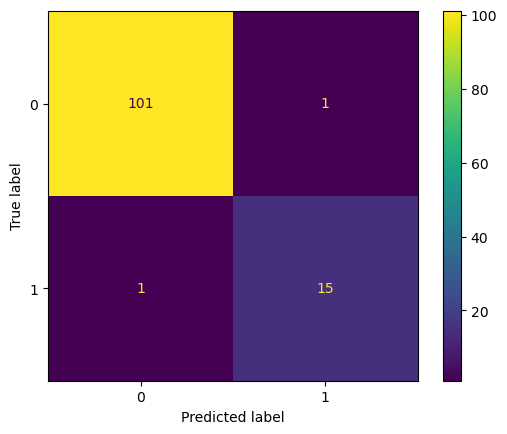

In [66]:
# Convert all to strings
y_test = [str(i) for i in y_test]
test_predictions = [str(i) for i in test_prediction]
labels = list(classifier.classes_.astype(str))

# Confusion matrix
cm = confusion_matrix(y_test, test_predictions, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot()


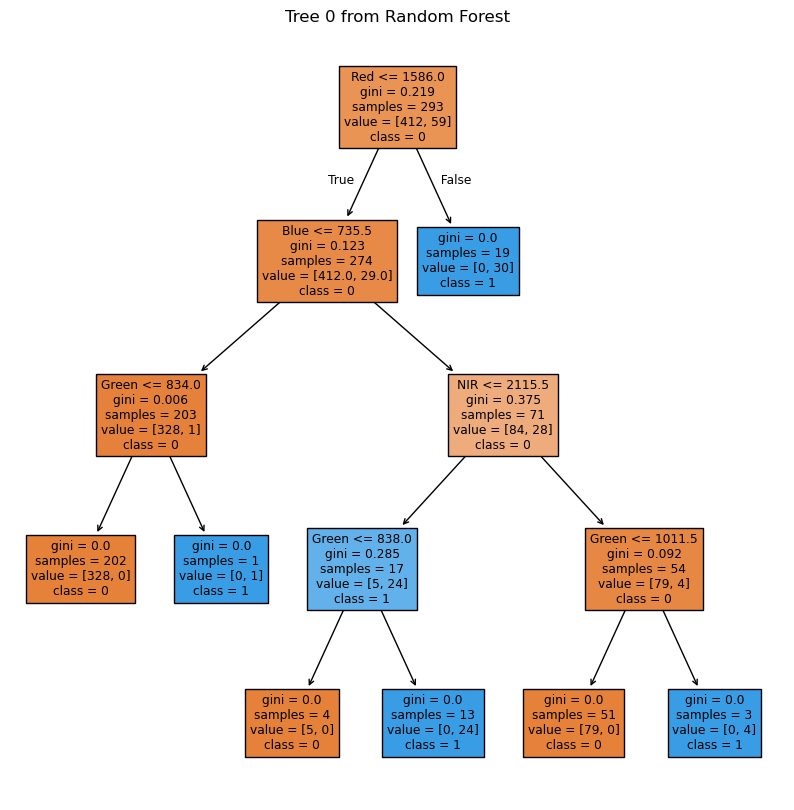

In [67]:
estimator = classifier.estimators_[0]  # <- get individual tree

# Plot it
fig, ax = plt.subplots(figsize=(10, 10))
tree.plot_tree(
    estimator,
    feature_names=['NIR', 'Red', 'Green', 'Blue'],
    class_names=classifier.classes_.astype(str),
    ax=ax,
    filled=True
)
plt.title("Tree 0 from Random Forest")
plt.show()

In [68]:
file_name = ['SentinelTinkitamDEC2020.tif']
data = []

for file in file_name:
    ds = gdal.Open(file)
    bands_array = ds.ReadAsArray(band_list=[7, 4, 3, 2])  # NIR, Red, Green, Blue
    for band in bands_array:
        data.append(band)

# Assign meaningful column names
df = pd.DataFrame({
    'NIR': data[0].ravel(),
    'Red': data[1].ravel(),
    'Green': data[2].ravel(),
    'Blue': data[3].ravel()
})

print(df.head())

    NIR   Red  Green  Blue
0  2743  1235    509   740
1  2975  1322    788   874
2  4159  1322    762   952
3  5272  1520    959  1228
4  4632  1520   1010  1052


In [69]:
random_map =classifier.predict(df)
random_map

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

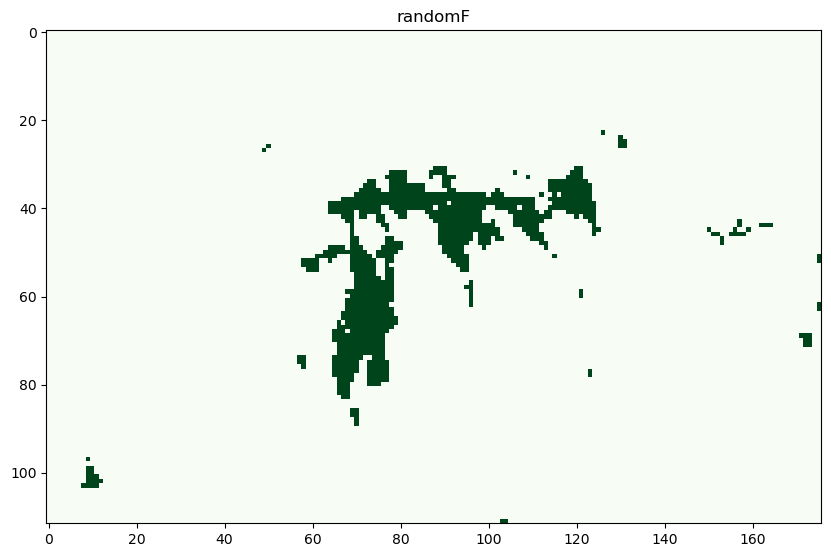

In [70]:
random_map= random_map.reshape(112,176)


plt.figure(figsize=(10,10))
plt.title('randomF')
plt.imshow(random_map, cmap='Greens')

In [8]:
os. chdir(r'F:\CTECH\GEOINT\honors 2nd sem\data')
file_name= 'aster_sikkim.tiff'
ds= gdal.Open(file_name)

In [9]:
band = ds.GetRasterBand(1)
data = band.ReadAsArray()
print(data)

[[5749 5759 5769 ... 5011 5007 5009]
 [5745 5750 5759 ... 5018 5013 5018]
 [5742 5747 5754 ... 5026 5025 5023]
 ...
 [1945 1963 1973 ... 1156 1154 1150]
 [1951 1965 1974 ... 1136 1133 1133]
 [1947 1959 1969 ... 1123 1121 1121]]


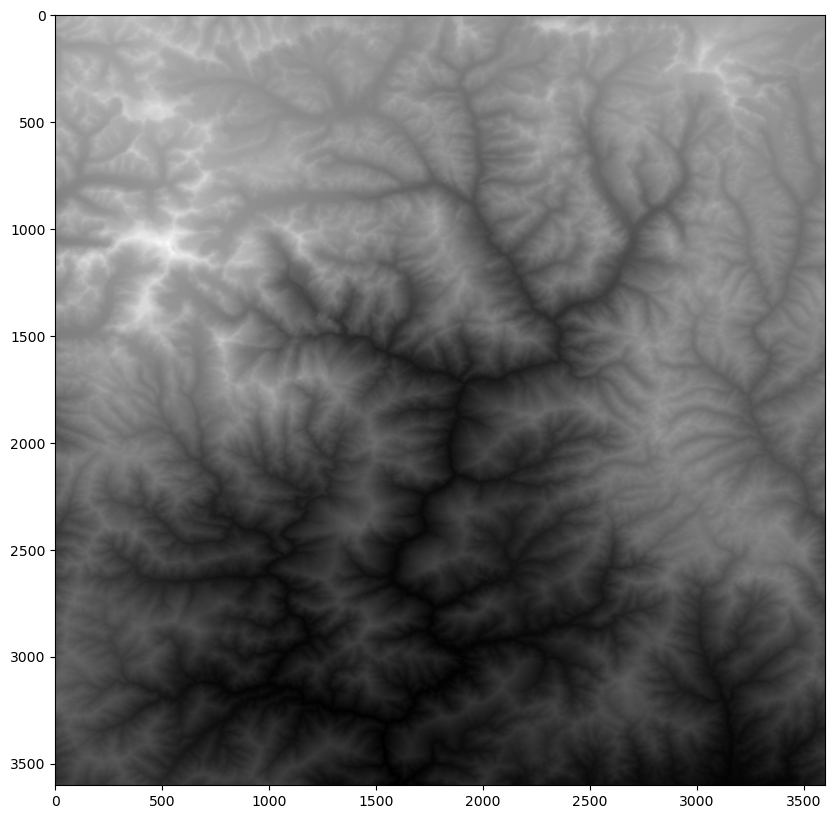

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
plt.imshow(data,cmap= 'gray')

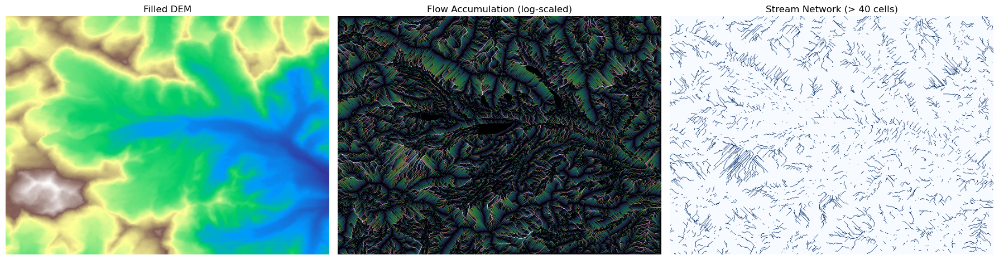

In [86]:
import richdem as rd
import matplotlib.pyplot as plt
import numpy as np
import os

# --- Step 1: Load DEM with NoData specified ---
dem_path = r'F:\CTECH\GEOINT\honors 2nd sem\data\demclip.tiff'
if not os.path.exists(dem_path):
    raise FileNotFoundError(f"DEM file not found at: {dem_path}")

# Load DEM with specified NoData
dem = rd.LoadGDAL(dem_path, no_data=-9999)

# --- Step 2: Fill depressions (sinks) ---
filled = rd.FillDepressions(dem)

# --- Step 3: Flow accumulation (D8)
flow_acc = rd.FlowAccumulation(filled, method='D8')

# --- Step 4: Extract streams by threshold
threshold = 40
streams = (flow_acc > threshold)

# --- Step 5: Plot the results ---
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

axs[0].imshow(filled, cmap='terrain')
axs[0].set_title("Filled DEM")
axs[0].axis('off')

axs[1].imshow(np.log1p(flow_acc), cmap='cubehelix')
axs[1].set_title("Flow Accumulation (log-scaled)")
axs[1].axis('off')

axs[2].imshow(streams, cmap='Blues')
axs[2].set_title(f"Stream Network (> {threshold} cells)")
axs[2].axis('off')

plt.tight_layout()
plt.show()


Pour point at: (282, 175)


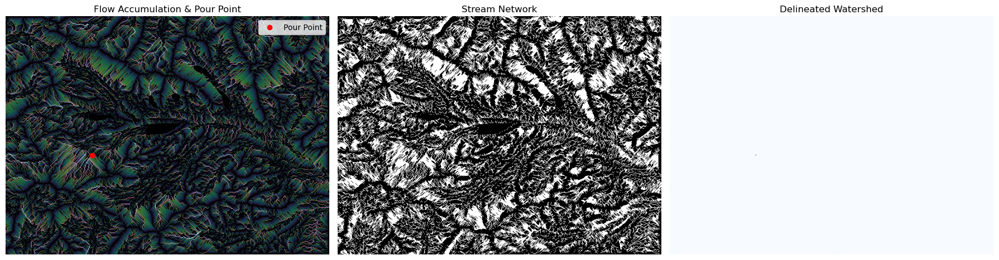

In [88]:
import richdem as rd
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
import os

# --- Step 1: Load and preprocess DEM ---
dem_path = r'F:\CTECH\GEOINT\honors 2nd sem\data\demclip.tiff'
dem = rd.LoadGDAL(dem_path, no_data=-9999)
filled = rd.FillDepressions(dem)
flow_acc = rd.FlowAccumulation(filled, method='D8')

# --- Step 2: Define pour point location (x, y) in array coordinates ---
# Example: Choose the cell with maximum flow accumulation
pour_point_index = np.unravel_index(np.argmax(flow_acc), flow_acc.shape)
print(f"Pour point at: {pour_point_index}")

# --- Step 3: Create binary mask of stream area upstream of pour point ---
# Use a threshold to define stream network (adjustable)
stream_threshold = 5
stream_mask = (flow_acc > stream_threshold)

# --- Step 4: Label connected streams ---
labeled_streams, num_labels = ndimage.label(stream_mask)

# --- Step 5: Get label of pour point stream
pour_point_label = labeled_streams[pour_point_index]

# --- Step 6: Extract watershed area (connected to pour point) ---
watershed_mask = (labeled_streams == pour_point_label)

# --- Step 7: Plot the results ---
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

axs[0].imshow(np.log1p(flow_acc), cmap='cubehelix')
axs[0].scatter(pour_point_index[1], pour_point_index[0], c='red', label='Pour Point')
axs[0].set_title("Flow Accumulation & Pour Point")
axs[0].legend()
axs[0].axis('off')

axs[1].imshow(stream_mask, cmap='gray')
axs[1].set_title("Stream Network")
axs[1].axis('off')

axs[2].imshow(watershed_mask, cmap='Blues')
axs[2].set_title("Delineated Watershed")
axs[2].axis('off')

plt.tight_layout()
plt.show()


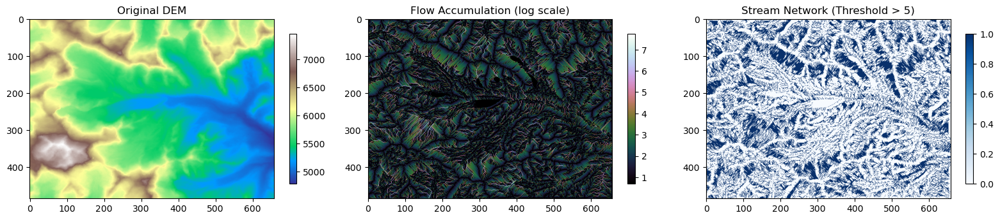

In [87]:
import richdem as rd
import numpy as np
import matplotlib.pyplot as plt

# === Step 1: Load DEM ===
dem_path = r'F:\CTECH\GEOINT\honors 2nd sem\data\demclip.tiff'
dem = rd.LoadGDAL(dem_path, no_data=-9999)

# === Step 2: Fill depressions ===
filled_dem = rd.FillDepressions(dem)

# === Step 3: Compute Flow Accumulation with explicit method ===
flow_acc = rd.FlowAccumulation(filled_dem, method='D8')  # Valid methods: D8, OCallaghanD8, Rho8, etc.

# === Step 4: Threshold stream network ===
threshold = 5  # Adjust depending on DEM resolution and area
stream_mask = (flow_acc > threshold).astype(np.uint8)

# === Step 5: Visualize ===
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(dem, cmap='terrain')
plt.title('Original DEM')
plt.colorbar(shrink=0.5)

plt.subplot(1, 3, 2)
plt.imshow(np.log1p(flow_acc), cmap='cubehelix')
plt.title('Flow Accumulation (log scale)')
plt.colorbar(shrink=0.5)

plt.subplot(1, 3, 3)
plt.imshow(stream_mask, cmap='Blues')
plt.title(f'Stream Network (Threshold > {threshold})')
plt.colorbar(shrink=0.5)

plt.tight_layout()
plt.show()

# === Step 6: Save outputs ===
rd.SaveGDAL("filled_dem.tif", filled_dem)
rd.SaveGDAL("flow_accumulation.tif", flow_acc)
rd.SaveGDAL("stream_network.tif", stream_mask)


In [8]:
! pip install pysheds


[notice] A new release of pip is available: 24.3.1 -> 25.2
[notice] To update, run: C:\Users\ghosh\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


c:\Users\ghosh\miniconda3\envs\Raster3\lib\site-packages\pysheds\io.py:134: UserWarning: No `nodata` value detected. Defaulting to 0.
  warnings.warn('No `nodata` value detected. Defaulting to 0.')


✅ DEM loaded.


<Figure size 1000x800 with 0 Axes>

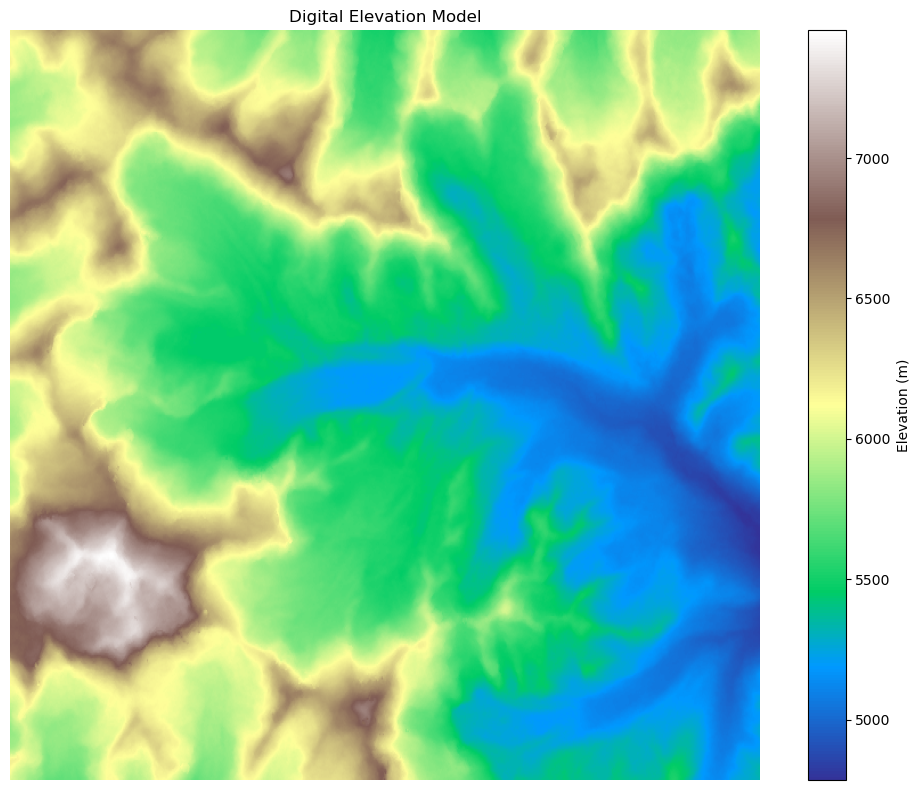

In [47]:
from pysheds.grid import Grid
import matplotlib.pyplot as plt

# Step 1: Create grid object
grid = Grid()

# Step 2: Load DEM (update your file path)
dem=grid.read_raster(r'F:\CTECH\GEOINT\honors 2nd sem\data\demclip.tiff')
print("✅ DEM loaded.")

# Step 3: Display the DEM
plt.figure(figsize=(10, 8))
plt.imshow(dem, cmap='terrain', extent=grid.extent)
plt.colorbar(label='Elevation (m)')
plt.title('Digital Elevation Model')
plt.axis('off')
plt.tight_layout()
plt.show()


c:\Users\ghosh\miniconda3\envs\Raster3\lib\site-packages\pysheds\io.py:134: UserWarning: No `nodata` value detected. Defaulting to 0.
  warnings.warn('No `nodata` value detected. Defaulting to 0.')


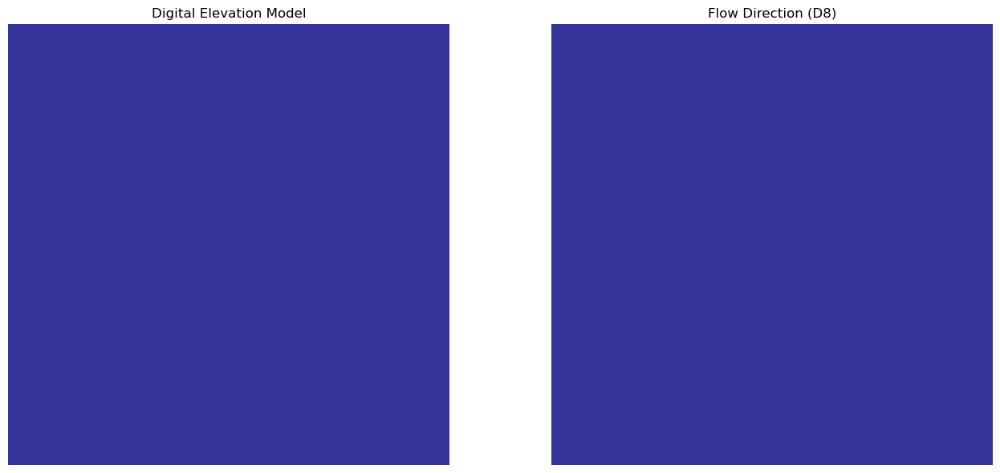

In [84]:
from pysheds.grid import Grid
import matplotlib.pyplot as plt

# Step 2: Load DEM (with a name)
dem= grid.read_raster(r'F:\CTECH\GEOINT\honors 2nd sem\data\demclip.tiff', no_data=-9999)

filled_dem = grid.fill_depressions(dem)

# Step 3: Compute flow direction (D8)
flowdir= grid.flowdir(filled_dem, dirmap= (64,128,1,2,4,8,16,32))

# === Step 3: Compute Flow Accumulation with explicit method ===
flow_acc = grid.accumulation(flowdir, method='D8')  # Valid methods: D8, OCallaghanD8, Rho8, etc.



# Step 4: Plot both DEM and flow direction
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Plot DEM
axs[0].imshow(flowdir, cmap='terrain', extent=grid.extent)
axs[0].set_title('Digital Elevation Model')
axs[0].axis('off')

# Plot Flow Direction
axs[1].imshow(np.log1p(flow_acc), cmap='terrain', extent=grid.extent)
axs[1].set_title('Flow Direction (D8)')
axs[1].axis('off')

plt.tight_layout()
plt.show()


In [5]:
! pip install whitebox

In [6]:
! pip install geopandas

.\whitebox_tools.exe --run="FillDepressions" --wd="F:\CTECH\GEOINT\honors 2nd sem\data" --dem='F:\CTECH\GEOINT\honors 2nd sem\data\ASTGTMV003_N27E088_dem.tif' --output='F:\CTECH\GEOINT\honors 2nd sem\data\filled_dem.tif' --fix_flats -v --compress_rasters=False

******************************
* Welcome to FillDepressions *
* Powered by WhiteboxTools   *
* www.whiteboxgeo.com        *
******************************
Reading data...
Finding pit cells: 25%
Finding pit cells: 50%
Finding pit cells: 75%
Finding pit cells: 100%
Filling depressions: 0%
Filling depressions: 1%
Filling depressions: 2%
Filling depressions: 3%
Filling depressions: 4%
Filling depressions: 5%
Filling depressions: 6%
Filling depressions: 7%
Filling depressions: 8%
Filling depressions: 9%
Filling depressions: 10%
Filling depressions: 11%
Filling depressions: 12%
Filling depressions: 13%
Filling depressions: 14%
Filling depressions: 15%
Filling depressions: 16%
Filling depressions: 17%
Filling depressions: 18%
Filling d

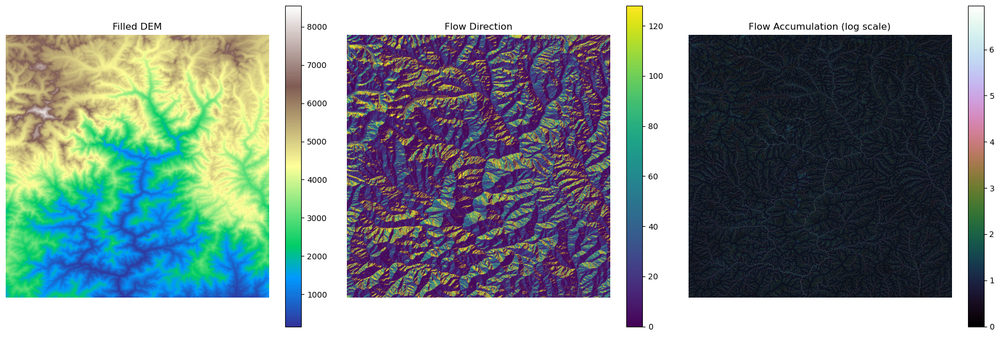

In [59]:
from whitebox.whitebox_tools import WhiteboxTools
import matplotlib.pyplot as plt
import rasterio

# === Step 1: Setup WhiteboxTools ===
wbt = WhiteboxTools()
wbt.verbose = True
wbt.work_dir = r"F:\CTECH\GEOINT\honors 2nd sem\data"

# === Step 2: Set DEM path ===
dem = r"F:\CTECH\GEOINT\honors 2nd sem\data\ASTGTMV003_N27E088_dem.tif"
filled_dem = r"F:\CTECH\GEOINT\honors 2nd sem\data\filled_dem.tif"
flow_dir = r"F:\CTECH\GEOINT\honors 2nd sem\data\flow_direction.tif"
flow_acc = r"F:\CTECH\GEOINT\honors 2nd sem\data\flow_accumulation.tif"

# === Step 3: Fill depressions ===
wbt.fill_depressions(dem, filled_dem)

# === Step 4: Compute D8 flow direction ===
wbt.d8_pointer(filled_dem, flow_dir)

# === Step 5: Compute D8 flow accumulation ===
wbt.d8_flow_accumulation(filled_dem, flow_acc, out_type="cells")

# === Step 6: Visualize DEM, Flow Direction, and Flow Accumulation ===
def plot_raster(filepath, title, cmap='terrain', log=False):
    with rasterio.open(filepath) as src:
        img = src.read(1)
        if log:
            img = img.astype(float)
            img[img <= 0] = float('nan')
            img = np.log10(img)
        plt.imshow(img, cmap=cmap)
        plt.title(title)
        plt.colorbar()
        plt.axis('off')

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_raster(dem, "Filled DEM", cmap="terrain")

plt.subplot(1, 3, 2)
plot_raster(flow_dir, "Flow Direction", cmap="viridis")

plt.subplot(1, 3, 3)
plot_raster(flow_acc, "Flow Accumulation (log scale)", cmap="cubehelix", log=True)

plt.tight_layout()
plt.show()


.\whitebox_tools.exe --run="FillDepressions" --wd="F:\CTECH\GEOINT\honors 2nd sem\data" --dem='F:\CTECH\GEOINT\honors 2nd sem\data\ASTGTMV003_N27E088_dem.tif' --output='F:\CTECH\GEOINT\honors 2nd sem\data\filled_dem.tif' --fix_flats -v --compress_rasters=False

******************************
* Welcome to FillDepressions *
* Powered by WhiteboxTools   *
* www.whiteboxgeo.com        *
******************************
Reading data...
Finding pit cells: 25%
Finding pit cells: 50%
Finding pit cells: 75%
Finding pit cells: 100%
Filling depressions: 0%
Filling depressions: 1%
Filling depressions: 2%
Filling depressions: 3%
Filling depressions: 4%
Filling depressions: 5%
Filling depressions: 6%
Filling depressions: 7%
Filling depressions: 8%
Filling depressions: 9%
Filling depressions: 10%
Filling depressions: 11%
Filling depressions: 12%
Filling depressions: 13%
Filling depressions: 14%
Filling depressions: 15%
Filling depressions: 16%
Filling depressions: 17%
Filling depressions: 18%
Filling d

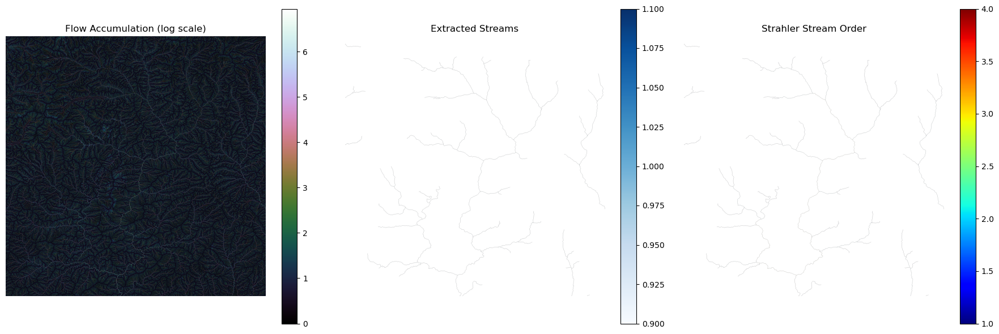

In [75]:
from whitebox.whitebox_tools import WhiteboxTools
import matplotlib.pyplot as plt
import rasterio
import numpy as np

# === Set up WhiteboxTools ===
wbt = WhiteboxTools()
wbt.work_dir = r"F:\CTECH\GEOINT\honors 2nd sem\data"  # Your working folder

# === Input/Output Files ===
dem = r"F:\CTECH\GEOINT\honors 2nd sem\data\ASTGTMV003_N27E088_dem.tif"
filled_dem = r"F:\CTECH\GEOINT\honors 2nd sem\data\filled_dem.tif"
flow_dir = r"F:\CTECH\GEOINT\honors 2nd sem\data\flow_direction.tif"
flow_acc = r"F:\CTECH\GEOINT\honors 2nd sem\data\flow_accumulation.tif"
streams = r"F:\CTECH\GEOINT\honors 2nd sem\data\streams.tif"
strahler = r"F:\CTECH\GEOINT\honors 2nd sem\data\strahler_order.tif"
streams_shapefile = r"F:\CTECH\GEOINT\honors 2nd sem\data\streams.shp"


# === Step 1: Fill depressions ===
wbt.fill_depressions(dem, filled_dem)

# === Step 2: Flow direction (D8) ===
wbt.d8_pointer(filled_dem, flow_dir)

# === Step 3: Flow accumulation (cells) ===
wbt.d8_flow_accumulation(filled_dem, flow_acc, out_type='cells')

# === Step 4: Extract streams using a threshold ===
threshold = 90000  # Adjust this based on DEM resolution
wbt.extract_streams(flow_acc, streams, threshold)

# === Step 5: Compute Strahler Stream Order ===
wbt.strahler_stream_order(flow_dir, streams, strahler)

wbt.raster_streams_to_vector(streams, flow_dir, streams_shapefile)

# === Step 6: Display results ===
def plot_raster(filepath, title, cmap='terrain', log=False):
    with rasterio.open(filepath) as src:
        img = src.read(1).astype(float)
        img[img == src.nodata] = np.nan
        if log:
            img[img <= 0] = np.nan
            img = np.log10(img)
        plt.imshow(img, cmap=cmap)
        plt.title(title)
        plt.colorbar()
        plt.axis('off')

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_raster(flow_acc, "Flow Accumulation (log scale)", cmap="cubehelix", log=True)

plt.subplot(1, 3, 2)
plot_raster(streams, "Extracted Streams", cmap="Blues")

plt.subplot(1, 3, 3)
plot_raster(strahler, "Strahler Stream Order", cmap="jet")

plt.tight_layout()
plt.show()


In [76]:
from whitebox.whitebox_tools import WhiteboxTools
import rasterio
import geopandas as gpd

# === Set paths ===
streams_raster = r"F:\CTECH\GEOINT\honors 2nd sem\data\streams.tif"
flow_dir = r"F:\CTECH\GEOINT\honors 2nd sem\data\flow_direction.tif"
streams_shp = r"F:\CTECH\GEOINT\honors 2nd sem\data\streams.shp"

# === Step: Convert raster streams to vector ===
wbt = WhiteboxTools()
wbt.work_dir = r"F:\CTECH\GEOINT\honors 2nd sem\data"
wbt.raster_streams_to_vector(streams_raster, flow_dir, streams_shp)

# === Step: Assign projection from original DEM ===
# Read CRS from DEM
with rasterio.open(flow_dir) as src:
    dem_crs = src.crs  # This gives the CRS like 'EPSG:32645'

# Load the shapefile
gdf = gpd.read_file(streams_shp)

# Assign CRS if missing or overwrite to ensure correct
gdf.set_crs(dem_crs, inplace=True, allow_override=True)

# Save shapefile with .prj (projection info)
gdf.to_file(streams_shp)

print(f"✅ Shapefile saved with projection: {dem_crs}")


.\whitebox_tools.exe --run="RasterStreamsToVector" --wd="F:\CTECH\GEOINT\honors 2nd sem\data" --streams='F:\CTECH\GEOINT\honors 2nd sem\data\streams.tif' --d8_pntr='F:\CTECH\GEOINT\honors 2nd sem\data\flow_direction.tif' --output='F:\CTECH\GEOINT\honors 2nd sem\data\streams.shp' -v --compress_rasters=False

************************************
* Welcome to RasterStreamsToVector *
* Powered by WhiteboxTools         *
* www.whiteboxgeo.com              *
************************************
Reading pointer data...
Reading streams data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progre

<Figure size 2000x1500 with 0 Axes>

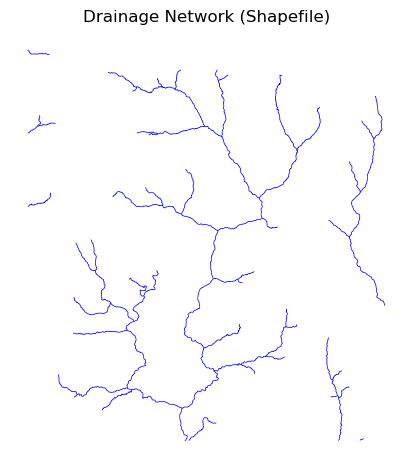

In [77]:
import geopandas as gpd

# === Load and display the streams shapefile ===
streams_shapefile = r"F:\CTECH\GEOINT\honors 2nd sem\data\streams.shp"
gdf = gpd.read_file(streams_shapefile)

# === Plot the shapefile ===
plt.figure(figsize=(20, 15))
gdf.plot(color='blue', linewidth=0.5)
plt.title("Drainage Network (Shapefile)")
plt.axis('off')
plt.tight_layout()
plt.show()


✅ Shapefile loaded.
Available columns: Index(['FID', 'STRM_VAL', 'geometry'], dtype='object')
✅ Found 80 third-order stream segments.
✅ Pour points saved to: F:\CTECH\GEOINT\honors 2nd sem\data\pour_points_3rd_order.shp


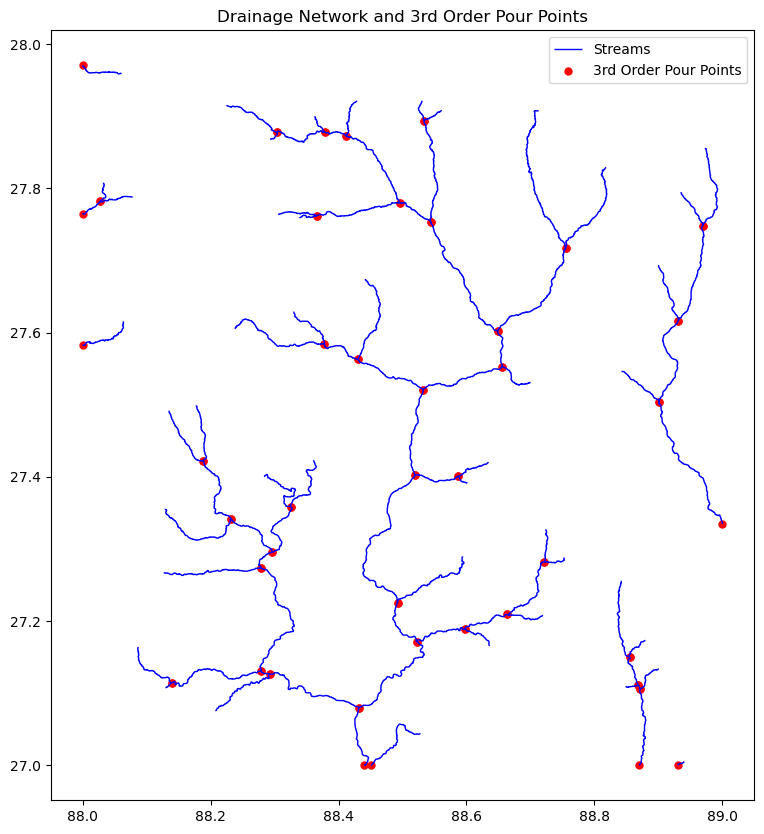

In [78]:
import geopandas as gpd
from shapely.geometry import Point
import os
import matplotlib.pyplot as plt

# === SET FILE PATHS ===
drainage_shp_path = r"F:\CTECH\GEOINT\honors 2nd sem\data\streams.shp"
output_dir = r"F:\CTECH\GEOINT\honors 2nd sem\data"
pour_points_path = os.path.join(output_dir, "pour_points_3rd_order.shp")

# === Create output directory ===
os.makedirs(output_dir, exist_ok=True)

# === STEP 1: Read drainage shapefile ===
drainage = gpd.read_file(drainage_shp_path)
print("✅ Shapefile loaded.")
print("Available columns:", drainage.columns)

# === STEP 2: Filter 3rd order streams ===
third_order = drainage[drainage['STRM_VAL'] == 1]
print(f"✅ Found {len(third_order)} third-order stream segments.")

# === STEP 3: Extract endpoints of each line ===
# We'll take the downstream end of each line
junction_points = third_order.copy()
junction_points['geometry'] = third_order.geometry.apply(lambda geom: Point(geom.coords[-1]))  # downstream point

# === STEP 4: Save pour points with projection ===
junction_points = junction_points.set_crs(drainage.crs)  # ensure CRS matches
junction_points.to_file(pour_points_path)
print(f"✅ Pour points saved to: {pour_points_path}")

# === STEP 5: Display the stream and pour points ===
fig, ax = plt.subplots(figsize=(10, 10))
drainage.plot(ax=ax, color='blue', linewidth=1, label='Streams')
junction_points.plot(ax=ax, color='red', markersize=25, label='3rd Order Pour Points')
ax.set_title("Drainage Network and 3rd Order Pour Points")
ax.legend()
plt.show()


In [79]:
import geopandas as gpd
import rasterio
from whitebox.whitebox_tools import WhiteboxTools
import os

# === Set Working Directory ===
wbt = WhiteboxTools()
wbt.work_dir = r"F:\CTECH\GEOINT\honors 2nd sem\data"  # update path accordingly

# === Input Files ===
pour_point_shp = os.path.join(wbt.work_dir, "pour_points_3rd_order.shp")         # your pour point
flow_accum = os.path.join(wbt.work_dir, "flow_accumulation.tif")              # flow accumulation raster
flow_dir = os.path.join(wbt.work_dir, "flow_direction.tif")                  # D8 flow direction raster

# === Step 1: Snap Pour Point to Stream (Optional but recommended) ===
#snapped_pour = os.path.join(wbt.work_dir, "snapped_pour.shp")
#wbt.snap_pour_points(pour_point_shp, flow_accum, snapped_pour, snap_dist=100)

# === Step 2: Delineate Watershed in Raster ===
watershed_raster = os.path.join(wbt.work_dir, "watershed.tif")
wbt.watershed(flow_dir, pour_point_shp, watershed_raster)

# === Step 3: Convert Raster to Vector (Polygon) ===
watershed_vector = os.path.join(wbt.work_dir, "watershed.shp")
wbt.raster_to_vector_polygons(watershed_raster, watershed_vector)

print("✅ Watershed delineation complete. Vector saved as:", watershed_vector)





.\whitebox_tools.exe --run="Watershed" --wd="F:\CTECH\GEOINT\honors 2nd sem\data" --d8_pntr='F:\CTECH\GEOINT\honors 2nd sem\data\flow_direction.tif' --pour_pts='F:\CTECH\GEOINT\honors 2nd sem\data\pour_points_3rd_order.shp' --output='F:\CTECH\GEOINT\honors 2nd sem\data\watershed.tif' -v --compress_rasters=False

****************************
* Welcome to Watershed     *
* Powered by WhiteboxTools *
* www.whiteboxgeo.com      *
****************************


Reading data...
Locating pour points: 0%
Locating pour points: 1%
Locating pour points: 2%
Locating pour points: 3%
Locating pour points: 5%
Locating pour points: 6%
Locating pour points: 7%
Locating pour points: 8%
Locating pour points: 10%
Locating pour points: 11%
Locating pour points: 12%
Locating pour points: 13%
Locating pour points: 15%
Locating pour points: 16%
Locating pour points: 17%
Locating pour points: 18%
Locating pour points: 20%
Locating pour points: 21%
Locating pour points: 22%
Locating pour points: 24%
Locating pour points: 25%
Locating pour points: 26%
Locating pour points: 27%
Locating pour points: 29%
Locating pour points: 30%
Locating pour points: 31%
Locating pour points: 32%
Locating pour points: 34%
Locating pour points: 35%
Locating pour points: 36%
Locating pour points: 37%
Locating pour points: 39%
Locating pour points: 40%
Locating pour points: 41%
Locating pour points: 43%
Locating pour points: 44%
Locating pour points: 45%
Locating pour points: 46%
Loca

c:\Users\ghosh\miniconda3\envs\Raster3\lib\site-packages\pyogrio\raw.py:198: RuntimeWarning: F:\CTECH\GEOINT\honors 2nd sem\data\watershed.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
C:\Users\ghosh\AppData\Local\Temp\ipykernel_10484\3908392252.py:23: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  plt.legend()


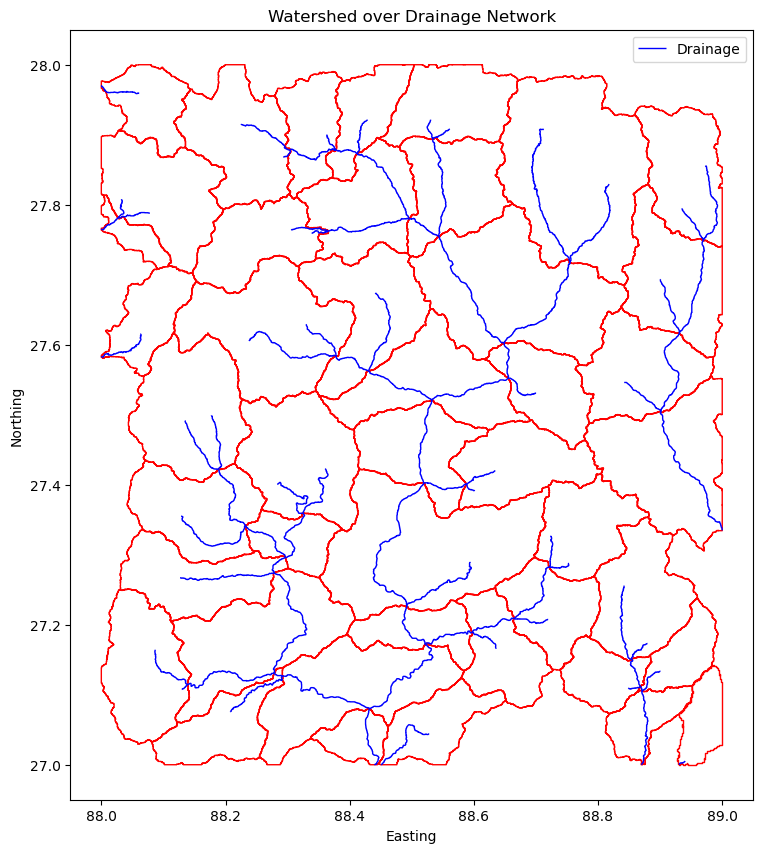

In [80]:
import geopandas as gpd
import matplotlib.pyplot as plt

# === File paths ===
drainage_path = r"F:\CTECH\GEOINT\honors 2nd sem\data\streams.shp"         # Drainage network
watershed_path = r"F:\CTECH\GEOINT\honors 2nd sem\data\watershed.shp"       # Watershed polygon

# === Read shapefiles ===
drainage_gdf = gpd.read_file(drainage_path)
watershed_gdf = gpd.read_file(watershed_path)

# === Ensure CRS match ===
if drainage_gdf.crs != watershed_gdf.crs:
    watershed_gdf = watershed_gdf.to_crs(drainage_gdf.crs)

# === Plot ===
fig, ax = plt.subplots(figsize=(10, 10))

drainage_gdf.plot(ax=ax, linewidth=1, color='blue', label="Drainage")
watershed_gdf.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=1, label="Watershed")

# Add legend and title
plt.legend()
plt.title("Watershed over Drainage Network")
plt.xlabel("Easting")
plt.ylabel("Northing")

plt.show()


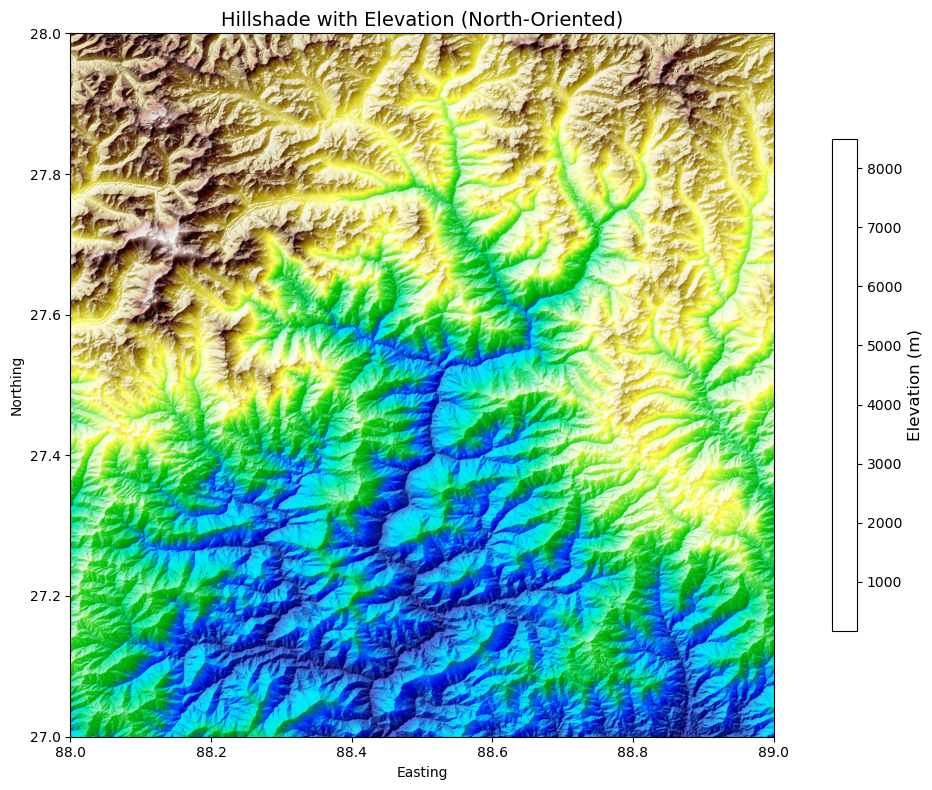

In [16]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
from rasterio.enums import Resampling

# === Load and downsample DEM to reduce memory usage ===
dem_path = r"F:\CTECH\GEOINT\honors 2nd sem\data\ASTGTMV003_N27E088_dem.tif"
with rasterio.open(dem_path) as src:
    # Downsample factor (2 = half resolution)
    scale_factor = 2
    out_shape = (int(src.height // scale_factor), int(src.width // scale_factor))

    dem = src.read(
        1,
        out_shape=out_shape,
        resampling=Resampling.bilinear
    ).astype(np.float32)

    transform = src.transform * src.transform.scale(
        (src.width / out_shape[1]),
        (src.height / out_shape[0])
    )

    dem[dem == src.nodata] = np.nan

# === Get spatial extent from transform ===
height, width = dem.shape
left, bottom = transform * (0, height)
right, top = transform * (width, 0)

# === Generate hillshade using LightSource ===
ls = LightSource(azdeg=315, altdeg=40)
rgb = ls.shade(dem, cmap=plt.cm.terrain, vert_exag=1, blend_mode='overlay')

# === Plotting with north-oriented axes ===
fig, ax = plt.subplots(figsize=(12, 8))

# Hillshade background
ax.imshow(rgb, extent=(left, right, bottom, top), origin='upper')

# Transparent DEM for colorbar
dem_img = ax.imshow(
    dem,
    cmap='terrain',
    extent=(left, right, bottom, top),
    origin='upper',
    alpha=0
)
cbar = plt.colorbar(dem_img, ax=ax, shrink=0.7)
cbar.set_label("Elevation (m)", fontsize=12)

# Labels and title
ax.set_title("Hillshade with Elevation (North-Oriented)", fontsize=14)
ax.set_xlabel("Easting")
ax.set_ylabel("Northing")

plt.tight_layout()
plt.show()


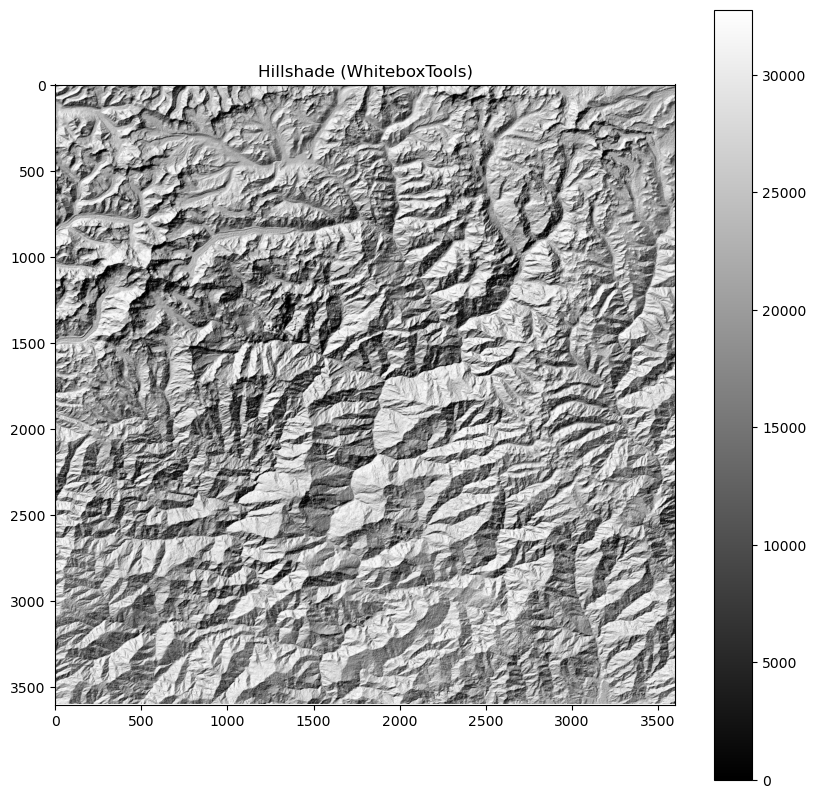

In [23]:
from whitebox.whitebox_tools import WhiteboxTools
import rasterio
import matplotlib.pyplot as plt

# === Set up WhiteboxTools ===
wbt = WhiteboxTools()
wbt.verbose = False
wbt.work_dir = r"F:\CTECH\GEOINT\honors 2nd sem\data"  # Change to your DEM folder

# === Input and Output Files ===
dem = "ASTGTMV003_N27E088_dem.tif"
hillshade = "hillshade.tif"

# === Generate Hillshade ===
wbt.hillshade(
    dem,
    output=hillshade,
    azimuth=315,         # Sun direction
    altitude=45,         # Sun elevation
    zfactor=1.0
)

# === Read and Display Hillshade ===
hillshade_path = f"{wbt.work_dir}\\{hillshade}"

with rasterio.open(hillshade_path) as src:
    hs = src.read(1)
    plt.figure(figsize=(10, 10))
    plt.imshow(hs, cmap='gray')
    plt.title("Hillshade (WhiteboxTools)")
    plt.axis('on')
    plt.colorbar()
    plt.show()


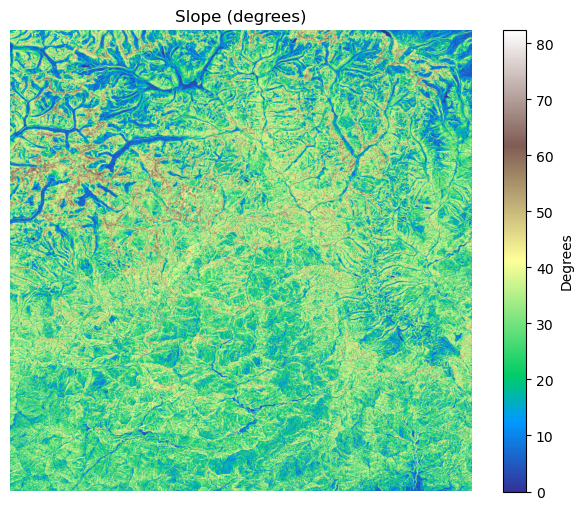

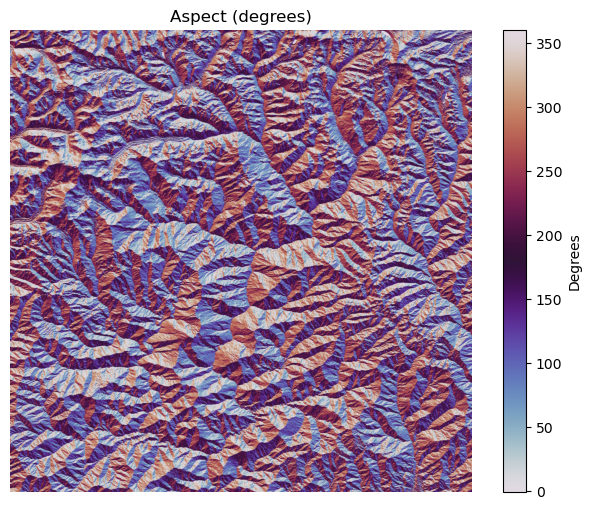

In [20]:
from whitebox.whitebox_tools import WhiteboxTools
import rasterio
import matplotlib.pyplot as plt

# === Set up WhiteboxTools ===
wbt = WhiteboxTools()
wbt.work_dir = r"F:\CTECH\GEOINT\honors 2nd sem\data"  # Set to your DEM folder
wbt.verbose = False

# === Input DEM ===
dem = "ASTGTMV003_N27E088_dem.tif"

# === Output filenames ===
slope_tif = "slope.tif"
aspect_tif = "aspect.tif"

# === Compute slope ===
wbt.slope(dem, slope_tif, zfactor=1.0)  # zfactor = 1.0 if DEM in degrees, adjust if in meters

# === Compute aspect ===
wbt.aspect(dem, aspect_tif)

# === Helper function to display raster ===
def display_raster(filepath, title, cmap='viridis'):
    with rasterio.open(filepath) as src:
        data = src.read(1)
        plt.figure(figsize=(8, 6))
        plt.imshow(data, cmap=cmap)
        plt.title(title)
        plt.colorbar(label="Degrees")
        plt.axis('off')
        plt.show()

# === Display Slope ===
display_raster(f"{wbt.work_dir}\\{slope_tif}", "Slope (degrees)", cmap='terrain')

# === Display Aspect ===
display_raster(f"{wbt.work_dir}\\{aspect_tif}", "Aspect (degrees)", cmap='twilight')
